# Modèle gaussien, frontière LDA / QDA

**Navigation** : [<< 2.3c-Regression-Grande-Dimension](2.3c-Regression-Grande-Dimension.ipynb) | [2.4-Arbres-Forets-Ensembles >>](2.4-Arbres-Forets-Ensembles.ipynb) | [Index 02-ML-Cours](README.md) | [Version Python](2.3d-Modele-Gaussien-LDA-QDA.ipynb)


Le [2.3b](2.3b-Naive-Bayes-Generatif.ipynb) faisait le pont génératif-discriminatif sous l'hypothèse d'**indépendance** des variables (Naive Bayes, covariance diagonale). Ici on relâche cette hypothèse et on regarde ce que devient la **frontière de décision** quand la covariance est complète.

- **LDA** (Linear Discriminant Analysis) : les classes partagent la **même covariance** `Σ`. La frontière est **linéaire**.
- **QDA** (Quadratic Discriminant Analysis) : chaque classe a sa **propre covariance** `Σ_c`. La frontière est **quadratique**.

Le point pédagogique : **l'hypothèse de covariance** n'est pas un détail technique — c'est elle qui décide si la frontière est droite ou courbe, et le bon modèle est celui dont l'hypothèse colle aux données.

> **Fil conducteur.** On dérive la frontière depuis la log-densité gaussienne, on implémente le LDA de zéro et on le vérifie contre `sklearn`, puis on construit **trois régimes contrôlés** où l'hypothèse de covariance change. On mesure lequel de LDA / QDA / logistique / Naive Bayes gagne dans chaque régime — c'est la **signature** d'une hypothèse, pas une course d'accuracy. Enfin on regarde le coût de QDA en grande dimension (où `Σ_c` devient singulière).

> **Note.** Ici *LDA* = **Linear Discriminant Analysis**. L'autre « LDA » (Latent Dirichlet Allocation) est déjà enseignée en topic modeling — hors sujet ici.


[Jumeau Python](2.3d-Modele-Gaussien-LDA-QDA.ipynb)

**Environnement C#** : Python.NET doit trouver CPython, NumPy et scikit-learn ; définir `PYTHONNET_PYDLL` et, selon l’installation, `PYTHONHOME`/`PYTHONPATH`. LDA from scratch et diagnostics sont calculés en C# avec MathNet ; les vrais LDA/QDA/sklearn et logistique restent les comparateurs.

In [53]:
#r "nuget: pythonnet, 3.1.0"
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Text.Json;
using System.Globalization;
using Python.Runtime;
using MathNet.Numerics.LinearAlgebra;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    var library = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (String.IsNullOrWhiteSpace(library))
    {
        throw new InvalidOperationException("Configurer Python.NET avec NumPy et scikit-learn.");
    }
    Runtime.PythonDLL = library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}
double[][] ReadMatrix(JsonElement element)
{
    return element.EnumerateArray().Select(row => row.EnumerateArray().Select(v => v.GetDouble()).ToArray()).ToArray();
}
int[] ReadInts(JsonElement element)
{
    return element.EnumerateArray().Select(v => v.GetInt32()).ToArray();
}
double[] ReadVector(JsonElement element)
{
    return element.EnumerateArray().Select(v => v.GetDouble()).ToArray();
}
PyModule py;
using (Py.GIL())
{
    py=Py.CreateScope();
    // Le tirage historique et les estimateurs de référence restent ceux de NumPy/sklearn.
    py.Exec(@"import json, numpy as np, sklearn, warnings
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
np.random.seed(0)
S=np.array([[1.,.6],[.6,1.]])
X=np.vstack([np.random.multivariate_normal([-1.5,0.],S,200),np.random.multivariate_normal([1.5,0.],S,200)])
y=np.r_[np.zeros(200,dtype=int),np.ones(200,dtype=int)]
sk=LinearDiscriminantAnalysis(solver='lsqr').fit(X,y)
ldav=json.dumps(dict(X=X.tolist(),y=y.tolist(),pred=sk.predict(X).tolist(),coef=sk.coef_[0].tolist(),intercept=float(sk.intercept_[0]),numpy=np.__version__,sklearn=sklearn.__version__))
models={'LDA':lambda:LinearDiscriminantAnalysis(),'QDA':lambda:QuadraticDiscriminantAnalysis(),'logistique':lambda:LogisticRegression(max_iter=8000),'NaiveBayes':lambda:GaussianNB()}
def make_pair(n,mu0,mu1,S0,S1,seed):
 r=np.random.default_rng(seed)
 x0=r.multivariate_normal(mu0,S0,n)
 x1=r.multivariate_normal(mu1,S1,n)
 return np.vstack([x0,x1]),np.r_[np.zeros(n,dtype=int),np.ones(n,dtype=int)]");
}
JsonElement Historical()
{
    using (Py.GIL())
    {
        return JsonDocument.Parse(py.Get("ldav").As<string>()).RootElement;
    }
}
var historical = Historical();
var initialX=ReadMatrix(historical.GetProperty("X"));
var initialY=ReadInts(historical.GetProperty("y"));
var initialSk=ReadInts(historical.GetProperty("pred"));
Console.WriteLine($"NumPy {historical.GetProperty("numpy").GetString()}, sklearn {historical.GetProperty("sklearn").GetString()} : {initialY.Length} observations historiques");

Installing Packages MathNet.Numerics pythonnet

NumPy 2.4.2, sklearn 1.9.1 : 400 observations historiques


### La question de ce notebook

Quatre classifieurs — LDA, QDA, régression logistique, Naive Bayes — vont être confrontés aux **mêmes données**, et les régimes font varier les covariances, mais aussi les moyennes et parfois la taille d'échantillon : les résultats sont des comparaisons de scénarios, pas un effet isolé. La thèse à éprouver : le meilleur modèle n'est pas le plus flexible, mais **celui dont l'hypothèse colle à la réalité des données**. Chaque section apporte une pièce : le calcul exact de la frontière (§1-2), des régimes contrôlés où l'on sait quelle hypothèse est vraie (§3), la géométrie des frontières (§4), la qualité des probabilités (§5), et la limite en grande dimension (§6).

### 1. Du modèle gaussien à la frontière

On suppose `P(x|c)` gaussien. La log-densité de la classe `c` est :

$$\log P(x|c) = -\tfrac{d}{2}\log(2\pi) - \tfrac{1}{2}\log|\Sigma_c| - \tfrac{1}{2}(x-\mu_c)^\top \Sigma_c^{-1}(x-\mu_c)$$

Le log-postérieur s'écrit `log P(c|x) = log P(x|c) + log π_c − log P(x)`. Pour comparer les classes, le dernier terme est commun : on peut donc utiliser les scores non normalisés `log P(x|c) + log π_c`. La **frontière** entre deux classes `k` et `l` est l'ensemble où `log P(k|x) = log P(l|x)` :

$$-\tfrac{1}{2}\log|\Sigma_k| - \tfrac{1}{2}(x-\mu_k)^\top \Sigma_k^{-1}(x-\mu_k) + \log\pi_k = -\tfrac{1}{2}\log|\Sigma_l| - \tfrac{1}{2}(x-\mu_l)^\top \Sigma_l^{-1}(x-\mu_l) + \log\pi_l$$

Deux cas décisifs :

- **`Σ_k = Σ_l = Σ`** (covariance partagée, **LDA**) : les termes `-1/2 log|Σ|` s'annulent, et le terme quadratique `x^⊤Σ^{-1}x` **présent des deux côtés s'élimine**. Il ne reste qu'une expression **linéaire** en `x` :

$$(\mu_k-\mu_l)^\top \Sigma^{-1} x - \tfrac{1}{2}(\mu_k^\top\Sigma^{-1}\mu_k - \mu_l^\top\Sigma^{-1}\mu_l) + \log\tfrac{\pi_k}{\pi_l} = 0$$

  La frontière est donc un **hyperplan** : direction `w = Σ^{-1}(μ_k - μ_l)`, offset `b = -1/2(μ_k^⊤Σ^{-1}μ_k - μ_l^⊤Σ^{-1}μ_l) + log(π_k/π_l)`.

- **`Σ_k ≠ Σ_l`** (**QDA**) : les termes `-1/2 log|Σ_c|` peuvent différer (des matrices distinctes peuvent aussi avoir le même déterminant) et les termes `x^⊤Σ_c^{-1}x` **ne se simplifient pas** — on garde un **terme quadratique** `x^⊤(Σ_k^{-1}-Σ_l^{-1})x`. La frontière est décrite par une équation **quadratique** ; selon les paramètres, elle peut être dégénérée ou vide.

**Le Naive Bayes de [2.3b](2.3b-Naive-Bayes-Generatif.ipynb)** est le cas particulier où chaque `Σ_c` est **diagonale** (indépendance) — une QDA *diagonalisée*, encore plus restrictive. On a donc un spectre : LDA (Σ partagée, frontière droite) → QDA (Σ propres, frontière courbe) → Naive Bayes (Σ diagonales, frontière courbe mais variables indépendantes).


In [54]:
public sealed class MyLda
{
    public int[] Classes { get; private set; }
    public Vector<double>[] Means { get; private set; }
    public Matrix<double> Covariance { get; private set; }
    public Matrix<double> Inverse { get; private set; }
    public double[] Priors { get; private set; }

    public MyLda Fit(double[][] rows, int[] labels)
    {
        int dimension = rows[0].Length;
        Classes = labels.Distinct().OrderBy(c => c).ToArray();
        Means = new Vector<double>[Classes.Length];
        Priors = new double[Classes.Length];
        Covariance = Matrix<double>.Build.Dense(dimension, dimension);
        for (int c = 0; c < Classes.Length; c++)
        {
            var indices = Enumerable.Range(0, labels.Length).Where(i => labels[i] == Classes[c]).ToArray();
            Priors[c] = indices.Length / (double)labels.Length;
            Means[c] = Vector<double>.Build.Dense(dimension, j => indices.Average(i => rows[i][j]));
            foreach (int i in indices)
            {
                var delta = Vector<double>.Build.DenseOfArray(rows[i]) - Means[c];
                Covariance += delta.OuterProduct(delta);
            }
        }
        // np.cov(..., rowvar=False) emploie n-1, distinct de l'estimateur sklearn lsqr.
        Covariance /= labels.Length - 1.0;
        Inverse = (Covariance + 1e-9 * Matrix<double>.Build.DenseIdentity(dimension)).Inverse();
        return this;
    }

    public double[][] Scores(double[][] rows)
    {
        var scores = new double[Classes.Length][];
        for (int c = 0; c < Classes.Length; c++)
        {
            scores[c] = new double[rows.Length];
            for (int i = 0; i < rows.Length; i++)
            {
                var delta = Vector<double>.Build.DenseOfArray(rows[i]) - Means[c];
                scores[c][i] = -0.5 * delta.DotProduct(Inverse * delta) + Math.Log(Priors[c]);
            }
        }
        return scores;
    }

    public int[] Predict(double[][] rows)
    {
        var scores = Scores(rows);
        return Enumerable.Range(0, rows.Length).Select(i =>
            Classes[Enumerable.Range(0, Classes.Length).OrderByDescending(c => scores[c][i]).First()]).ToArray();
    }
}
Console.WriteLine("LDA natif prêt.");

LDA natif prêt.


### Ce que le « de zéro » apporte ici

Réimplémenter le LDA rend explicites les choix de covariance poolée, de priors et de score gaussien. La cellule suivante compare les prédictions et les directions à `sklearn` sur un tirage partagé : c'est un contrôle empirique de cette implémentation, pas une preuve pour toutes les données. La covariance maison utilise `np.cov`, normalisée par `n−1` et régularisée, tandis que `lsqr` emploie une autre normalisation ; il faut donc comparer leurs valeurs numériques plutôt que supposer des coefficients identiques.


In [55]:
// Comparer la direction LDA aux mêmes données et expliciter la différence de normalisation.
var my = new MyLda().Fit(initialX,initialY);
var ownPrediction=my.Predict(initialX);
var ownW=my.Inverse*(my.Means[1]-my.Means[0]);
var referenceW=Vector<double>.Build.DenseOfArray(ReadVector(historical.GetProperty("coef")));
double cosine=ownW.DotProduct(referenceW)/(ownW.L2Norm()*referenceW.L2Norm());
Console.WriteLine($"Accuracy native={ownPrediction.Select((v,i)=>v==initialY[i]?1.0:0.0).Average():F4}, prédictions identiques={ownPrediction.SequenceEqual(initialSk)}");
Console.WriteLine($"w natif=[{ownW[0]:F3},{ownW[1]:F3}], sklearn=[{referenceW[0]:F3},{referenceW[1]:F3}], cosinus={cosine:F6}");
Console.WriteLine($"Intercept sklearn={historical.GetProperty("intercept").GetDouble():F3} ; np.cov utilise n−1, sklearn lsqr utilise n.");

Accuracy native=0.9800, prédictions identiques=True


w natif=[4.877,-2.913], sklearn=[4.889,-2.920], cosinus=1.000000


Intercept sklearn=-0.358 ; np.cov utilise n−1, sklearn lsqr utilise n.


### Lecture — un contrôle sur ce tirage

Le from-scratch et sklearn donnent la même accuracy `0,98` et les mêmes prédictions sur les 400 observations affichées. La direction `w=Σ⁻¹(μ₁−μ₀)` a un cosinus arrondi à `1,0` avec `coef_` de sklearn : les directions concordent sur cette expérience.

Les coefficients ne sont pas exactement identiques : `[4,877 ; −2,913]` contre `[4,889 ; −2,920]`. L'écart reflète notamment la normalisation `n−1` versus `n` ainsi que la petite régularisation de la version maison. Un bon accord sur ce tirage contrôle la formule et les prédictions observées, sans établir une égalité exacte des coefficients ni la correction sur toutes les données.


### Exercice 1 — implémenter le QDA de zéro

On généralise `MyLDA` en `MyQDA` : chaque classe garde sa **propre** covariance `Σ_c` et le terme quadratique `-1/2 log|Σ_c|` est **conservé** (il ne se simplifie plus). Écrire la version complète où `log P(c|x)` est calculé avec `Σ_c` (propre) **et** le terme `-1/2 log|Σ_c|`.


In [56]:
double[][] QdaScores(double[][] x,int[] y,double[][] test)
{
    // TODO : renvoyer les scores de chaque classe, avec covariance propre et log-déterminant.
    return null;
}
var qdaFixtures=new[]
{
    (new[]{new[]{-2.0,-1.0},new[]{-1.0,0.0},new[]{-1.5,1.0},new[]{-.5,.5},new[]{1.0,0.0},new[]{2.0,1.0},new[]{1.5,-1.0},new[]{.5,-.5}},new[]{0,0,0,0,1,1,1,1},new[]{new[]{-1.0,.1},new[]{.2,.5},new[]{1.0,-.3}}),
    (new[]{new[]{-3.0,0.0},new[]{-2.0,2.0},new[]{-1.0,-1.0},new[]{-2.0,-.5},new[]{0.0,2.0},new[]{1.0,1.0},new[]{2.0,3.0},new[]{3.0,2.0}},new[]{0,0,0,0,1,1,1,1},new[]{new[]{-2.0,1.0},new[]{1.0,2.0}})
};
var qdaAnswers=qdaFixtures.Select(f=>QdaScores(f.Item1,f.Item2,f.Item3)).ToArray();
if(qdaAnswers.All(a=>a==null))
{
    Console.WriteLine("Exercice 1 à compléter.");
}
else if(qdaAnswers.Any(a=>a==null))
{
    Console.WriteLine("Exercice 1 : à revoir");
}
else
{
    bool ok=true;
    for(int k=0;k<qdaFixtures.Length;k++)
    {
        var (x,y,test)=qdaFixtures[k];
        var answer=qdaAnswers[k];
        var classes=y.Distinct().OrderBy(v=>v).ToArray();
        if(answer.Length!=classes.Length || answer.Any(row=>row==null || row.Length!=test.Length))
        {
            ok=false;
            continue;
        }
        for(int c=0;c<classes.Length;c++)
        {
            var subset=Enumerable.Range(0,y.Length).Where(i=>y[i]==classes[c]).Select(i=>x[i]).ToArray();
            var mean=Vector<double>.Build.Dense(x[0].Length,j=>subset.Average(row=>row[j]));
            var covariance=Matrix<double>.Build.Dense(x[0].Length,x[0].Length);
            foreach(var row in subset)
            {
                var difference=Vector<double>.Build.DenseOfArray(row)-mean;
                covariance+=difference.OuterProduct(difference);
            }
            covariance=covariance/(subset.Length-1.0)+1e-9*Matrix<double>.Build.DenseIdentity(x[0].Length);
            var cholesky=covariance.Cholesky();
            double logdet=Math.Log(cholesky.Determinant);
            for(int j=0;j<test.Length;j++)
            {
                var difference=Vector<double>.Build.DenseOfArray(test[j])-mean;
                double expected=Math.Log(subset.Length/(double)y.Length)-.5*logdet-.5*difference.DotProduct(cholesky.Solve(difference));
                ok=ok && double.IsFinite(answer[c][j]) && Math.Abs(answer[c][j]-expected)<1e-9;
            }
        }
    }
    Console.WriteLine(ok ? "Exercice 1 : scores cohérents ; comparer aussi les prédictions" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


### 3. Trois régimes contrôlés — l'hypothèse de covariance décide

On construit trois jeux où les covariances et les moyennes changent ; le régime C réduit également la taille de l'échantillon :

- **Régime A — covariance partagée** : les deux classes sont tirées avec le **même** `Σ`. L'hypothèse LDA est **vraie** → la frontière linéaire est optimale.
- **Régime B — covariances propres** : `Σ_0` et `Σ_1` diffèrent (ici par le **signe de la corrélation**). L'hypothèse LDA est **fausse** → la frontière de Bayes a une équation quadratique, éventuellement dégénérée ; comparer les modèles sur le tirage.
- **Régime C — petit échantillon mal conditionné** : même structure que B mais avec très peu de points et des classes proches. QDA doit estimer `Σ_k` et `Σ_l` séparément — en petit `n`, le risque de **variance d'estimation** augmente ; la comparaison mesurée doit déterminer ce qui se produit ici.

On compare sur les **mêmes splits et graines** [2.3](2.3-Regression-lineaire-logistique.ipynb) : LDA, QDA, logistique (linéaire), Naive Bayes (gaussien diagonal).


### Le protocole avant les résultats

Trois régimes synthétiques : la covariance varie, ainsi que les moyennes entre A et B et la taille d'échantillon pour C. Régime A — covariances **identiques** entre classes (l'hypothèse LDA est vraie par construction) ; régime B — covariances **différentes** (elle est fausse) ; régime C — covariances différentes mais **très peu de points**. Chaque accuracy est moyennée sur **20 graines** avec son écart-type : les écarts-types décrivent la dispersion des runs, sans constituer un test statistique de différence. C'est ce dispositif — facteur contrôlé, répétition, barre d'erreur — qui autorisera la lecture d'après à parler de *signature de l'hypothèse* et non de loterie d'un split chanceux.

In [57]:
(double mean,double sd) MeanAndSd(double[] values)
{
    double mean=values.Average();
    return (mean,Math.Sqrt(values.Average(value=>Math.Pow(value-mean,2))));
}
void EvaluateRegime(string name,int nTrain,double[] mu0,double[] mu1,double[][] s0,double[][] s1)
{
    var methods=new[] { "LDA", "QDA", "logistique", "NaiveBayes" };
    var observations=methods.ToDictionary(method=>method,method=>new List<double>());
    using (Py.GIL())
    {
        py.Set("mu0_json",new PyString(JsonSerializer.Serialize(mu0)));
        py.Set("mu1_json",new PyString(JsonSerializer.Serialize(mu1)));
        py.Set("s0_json",new PyString(JsonSerializer.Serialize(s0)));
        py.Set("s1_json",new PyString(JsonSerializer.Serialize(s1)));
        py.Set("n_train",new PyInt(nTrain));
        py.Exec("mu0=json.loads(mu0_json);mu1=json.loads(mu1_json);S0=json.loads(s0_json);S1=json.loads(s1_json)");
    }
    for(int seed=0;seed<20;seed++)
    {
        int[] labels;
        using (Py.GIL())
        {
            py.Set("seed",new PyInt(seed));
            py.Exec(@"Xtr,ytr=make_pair(int(n_train),mu0,mu1,S0,S1,100+int(seed))
Xte,yte=make_pair(1000,mu0,mu1,S0,S1,200+int(seed))
labels_json=json.dumps(yte.tolist())");
            labels=ReadInts(JsonDocument.Parse(py.Get("labels_json").As<string>()).RootElement);
        }
        foreach(string method in methods)
        {
            int[] predicted;
            using (Py.GIL())
            {
                py.Set("model_name",new PyString(method));
                py.Exec("m=models[str(model_name)]().fit(Xtr,ytr);prediction_json=json.dumps(m.predict(Xte).tolist())");
                predicted=ReadInts(JsonDocument.Parse(py.Get("prediction_json").As<string>()).RootElement);
            }
            // L'accuracy est calculée en C#, à partir des véritables prédictions sklearn.
            observations[method].Add(predicted.Select((v,i)=>v==labels[i]?1.0:0.0).Average());
        }
    }
    Console.WriteLine($"=== {name} : {nTrain} exemples par classe, 20 graines ===");
    foreach(string method in methods)
    {
        var (mean,sd)=MeanAndSd(observations[method].ToArray());
        Console.WriteLine($"{method,-12} {mean:F4} ± {sd:F4}");
    }
}
var muA0=new[] {-1.5,0.0};
var muA1=new[] {1.5,0.0};
var shared=new[] {new[] {1.0,.6},new[] {.6,1.0}};
var muB0=new[] {-1.0,0.0};
var muB1=new[] {1.0,0.0};
var covarianceB0=new[] {new[] {1.0,.85},new[] {.85,1.0}};
var covarianceB1=new[] {new[] {1.0,-.85},new[] {-.85,1.0}};
EvaluateRegime("A — covariance partagée",200,muA0,muA1,shared,shared);
EvaluateRegime("B — covariances propres",200,muB0,muB1,covarianceB0,covarianceB1);
EvaluateRegime("C — petit échantillon",5,muB0,muB1,covarianceB0,covarianceB1);

=== A — covariance partagée : 200 exemples par classe, 20 graines ===


LDA          0.9699 ± 0.0033


QDA          0.9695 ± 0.0036


logistique   0.9697 ± 0.0038


NaiveBayes   0.9332 ± 0.0063


=== B — covariances propres : 200 exemples par classe, 20 graines ===


... (5 outputs left out)

LDA          0.8166 ± 0.0599


QDA          0.8364 ± 0.0583


logistique   0.8342 ± 0.0104


NaiveBayes   0.8046 ± 0.0622


### Lecture — la signature de l'hypothèse, pas une course d'accuracy

Mesuré sur **20 graines** (moyenne ± écart-type) :

- **Régime A** (Σ partagée) : LDA 0.9698, QDA 0.9695, logistique 0.9697 — **quasi-égaux** (~0.97, à 0.001 près). L'hypothèse de covariance partagée est vraie → la frontière linéaire suffit, et QDA n'apporte rien. Naive Bayes 0.9332 décroche seul (−3.7 pts) : il **ignore la corrélation** (diagonale), ce qui correspond à un écart observé sur ce régime ; une corrélation ne garantit pas à elle seule une perte de classification.
- **Régime B** (Σ propres) : QDA 0.9004 **devance** LDA 0.8434 de **+5.7 pts** ; logistique 0.8440 ≈ LDA (tous deux linéaires) ; Naive Bayes 0.8417. Sur ce régime B, la différence observée est d’environ 6 points ; des covariances distinctes ne garantissent pas cet avantage sur toute distribution ou tout échantillon.
- **Régime C** (petit n = 5/classe) : QDA 0.8373, LDA 0.8166 — mais écart-types **±0.06** : ces résumés seuls ne permettent pas de conclure statistiquement sur leur différence. En 2D, même à n=5, la différence de covariance est un signal assez fort pour que QDA ne s'effondre pas ; la logistique (0.8342, ±0.0104) est la plus stable. Le basculement « LDA survit, QDA s'effondre » n'apparaît pas en 2D mais **en grande dimension** (§6).


### Exercice 2 — trouver la frontière entre LDA et QDA

Faire varier la **taille du train** `n` (de 15 à 300) sur le régime B (covariances propres) et tracer l'accuracy de LDA vs QDA. Identifier le `n` à partir duquel QDA passe devant LDA.


In [58]:
double[][] CurveSizes(int[] sizes,int seed)
{
    // TODO : entraîner LDA/QDA sur le régime B, puis renvoyer les accuracies sur le test commun.
    return null;
}
var sizeFixtures=new[] {(new[] {15,30,60,120,200,300},42),(new[] {15,30},7)};
var sizeAnswers=sizeFixtures.Select(f=>CurveSizes(f.Item1,f.Item2)).ToArray();
if(sizeAnswers.All(a=>a==null))
{
    Console.WriteLine("Exercice 2 à compléter.");
}
else if(sizeAnswers.Any(a=>a==null))
{
    Console.WriteLine("Exercice 2 : à revoir");
}
else
{
    bool ok=true;
    for(int f=0;f<sizeFixtures.Length;f++)
    {
        var (sizes,seed)=sizeFixtures[f];
        var answer=sizeAnswers[f];
        if(answer.Length!=sizes.Length || answer.Any(row=>row==null || row.Length!=2))
        {
            ok=false;
            continue;
        }
        using (Py.GIL())
        {
            py.Set("ex_seed",new PyInt(seed));
            py.Exec(@"ex_mu0,ex_mu1=[-1.,0.],[1.,0.]
ex_s0,ex_s1=[[1.,.85],[.85,1.]],[[1.,-.85],[-.85,1.]]
ex_Xte,ex_yte=make_pair(1000,ex_mu0,ex_mu1,ex_s0,ex_s1,int(ex_seed)+1)");
        }
        for(int i=0;i<sizes.Length;i++)
        {
            double[] expected;
            using (Py.GIL())
            {
                py.Set("ex_size",new PyInt(sizes[i]));
                py.Exec(@"ex_Xtr,ex_ytr=make_pair(int(ex_size),ex_mu0,ex_mu1,ex_s0,ex_s1,int(ex_seed))
ex_result=json.dumps([float(np.mean(LinearDiscriminantAnalysis().fit(ex_Xtr,ex_ytr).predict(ex_Xte)==ex_yte)),float(np.mean(QuadraticDiscriminantAnalysis().fit(ex_Xtr,ex_ytr).predict(ex_Xte)==ex_yte))])");
                expected=ReadVector(JsonDocument.Parse(py.Get("ex_result").As<string>()).RootElement);
            }
            ok=ok && answer[i].Zip(expected,(v,e)=>double.IsFinite(v) && Math.Abs(v-e)<1e-10).All(v=>v);
        }
    }
    Console.WriteLine(ok ? "Exercice 2 : mesures correctes ; tracer et discuter le premier croisement" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


### 4. Frontières et projection supervisée

La frontière de chaque modèle n'est pas un détail : elle rend **visible** l'hypothèse de covariance.

La **projection supervisée** est la deuxième lecture : LDA projette sur l'axe **discriminant** `w = Σ^{-1}(μ_1-μ_0)` — celui qui sépare le mieux les classes — alors que le [2.6](2.6-Clustering-KMeans-PCA.ipynb) projette sur l'axe **de variance maximale** (non supervisé). On compare les deux sur les mêmes données.


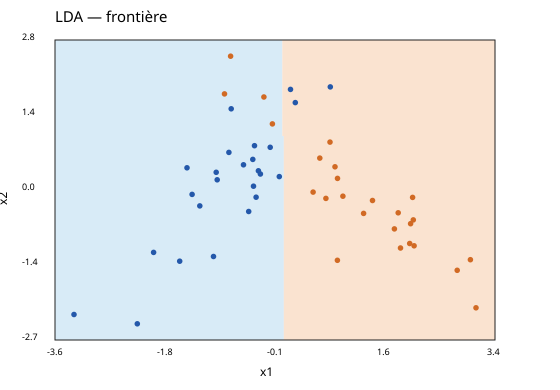

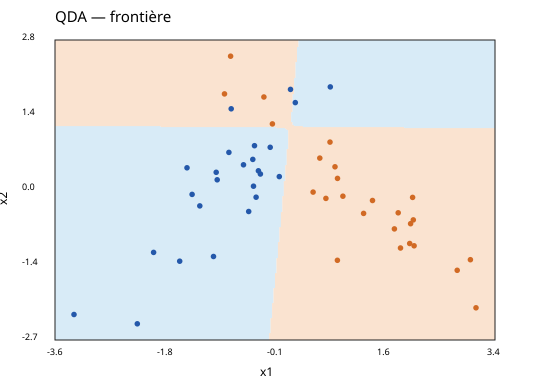

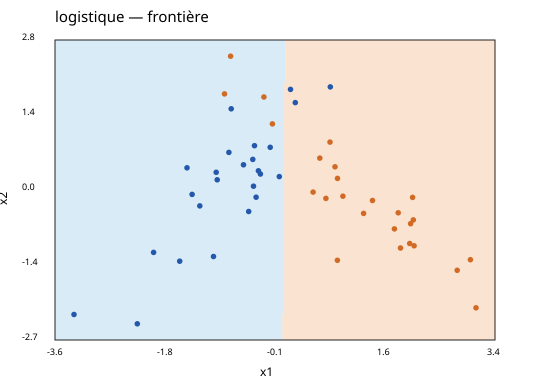

Trois frontières évaluées sur 300×300 points ; nuage de test sous-échantillonné comme la source.


In [59]:
public record LdaSvg(string Value);
Formatter.Register<LdaSvg>((value,writer)=>writer.Write(value.Value),"image/svg+xml");
var boundaryModels=new[] { "LDA", "QDA", "logistique" };
JsonElement boundaryData;
using (Py.GIL())
{
    // Régime B : 200 points d'entraînement et 500 points de test par classe.
    py.Exec(@"muB0,muB1=[-1.,0.],[1.,0.]
SB0,SB1=[[1.,.85],[.85,1.]],[[1.,-.85],[-.85,1.]]
XtrB,ytrB=make_pair(200,muB0,muB1,SB0,SB1,42)
XteB,yteB=make_pair(500,muB0,muB1,SB0,SB1,43)
viewX,viewY=XteB[::20],yteB[::20]
bound_json=json.dumps(dict(points=viewX.tolist(),labels=viewY.tolist(),xmin=float(viewX[:,0].min()-.3),xmax=float(viewX[:,0].max()+.3),ymin=float(viewX[:,1].min()-.3),ymax=float(viewX[:,1].max()+.3)))");
    boundaryData=JsonDocument.Parse(py.Get("bound_json").As<string>()).RootElement;
}
var boundaryPoints=ReadMatrix(boundaryData.GetProperty("points"));
var boundaryLabels=ReadInts(boundaryData.GetProperty("labels"));
double xmin=boundaryData.GetProperty("xmin").GetDouble(),xmax=boundaryData.GetProperty("xmax").GetDouble();
double ymin=boundaryData.GetProperty("ymin").GetDouble(),ymax=boundaryData.GetProperty("ymax").GetDouble();
var grid=new double[90000][];
for(int row=0;row<300;row++)
{
    for(int col=0;col<300;col++)
    {
        grid[row*300+col]=new[] {xmin+(xmax-xmin)*col/299.0,ymin+(ymax-ymin)*row/299.0};
    }
}
string PlotBoundary(string title,int[] prediction)
{
    const int left=55,top=40,width=440,height=300;
    var svg=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='560' height='390'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='55' y='22' font-size='15'>{title}</text>");
    for(int row=0;row<300;row++)
    {
        int start=0;
        for(int col=1;col<=300;col++)
        {
            if(col<300 && prediction[row*300+col]==prediction[row*300+start]) continue;
            string fill=prediction[row*300+start]==0 ? "#d8ebf7" : "#fae3d0";
            double x=left+start*width/300.0,y=top+(299-row)*height/300.0;
            svg.Append($"<rect x='{x:0.00}' y='{y:0.00}' width='{(col-start)*width/300.0+.1:0.00}' height='{height/300.0+.1:0.00}' fill='{fill}'/>");
            start=col;
        }
    }
    for(int i=0;i<boundaryPoints.Length;i++)
    {
        double x=left+(boundaryPoints[i][0]-xmin)/(xmax-xmin)*width;
        double y=top+(ymax-boundaryPoints[i][1])/(ymax-ymin)*height;
        string fill=boundaryLabels[i]==0 ? "#2458aa" : "#d16a24";
        svg.Append($"<circle cx='{x:0.0}' cy='{y:0.0}' r='2.8' fill='{fill}'/>");
    }
    for(int tick=0;tick<=4;tick++)
    {
        double fraction=tick/4.0;
        svg.Append($"<text x='{left+fraction*width-8:0.0}' y='355' font-size='9'>{xmin+fraction*(xmax-xmin):0.0}</text><text x='22' y='{top+(1-fraction)*height:0.0}' font-size='9'>{ymin+fraction*(ymax-ymin):0.0}</text>");
    }
    svg.Append($"<rect x='{left}' y='{top}' width='{width}' height='{height}' fill='none' stroke='#222'/><text x='260' y='376' font-size='12'>x1</text><text x='7' y='205' font-size='12' transform='rotate(-90 7 205)'>x2</text></g></svg>");
    return svg.ToString();
}
using (Py.GIL())
{
    py.Set("grid_json",new PyString(JsonSerializer.Serialize(grid)));
    py.Exec("grid=np.asarray(json.loads(grid_json))");
}
foreach(string name in boundaryModels)
{
    int[] prediction;
    using (Py.GIL())
    {
        py.Set("model_name",new PyString(name));
        py.Exec("m=models[str(model_name)]().fit(XtrB,ytrB); field_json=json.dumps(m.predict(grid).tolist())");
        prediction=ReadInts(JsonDocument.Parse(py.Get("field_json").As<string>()).RootElement);
    }
    display(new LdaSvg(PlotBoundary(name+" — frontière",prediction)),"image/svg+xml");
}
Console.WriteLine("Trois frontières évaluées sur 300×300 points ; nuage de test sous-échantillonné comme la source.");

cos(w_LDA,w_PC1)=-0.0004, variance x1=0.35, x2=9.73


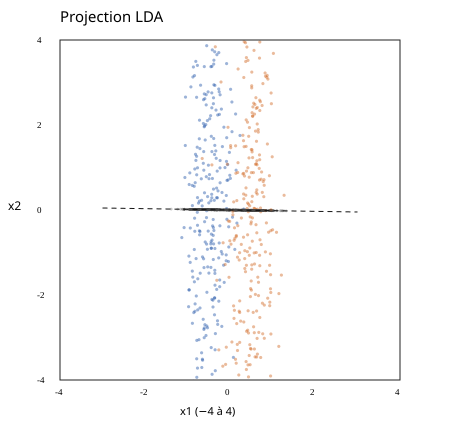

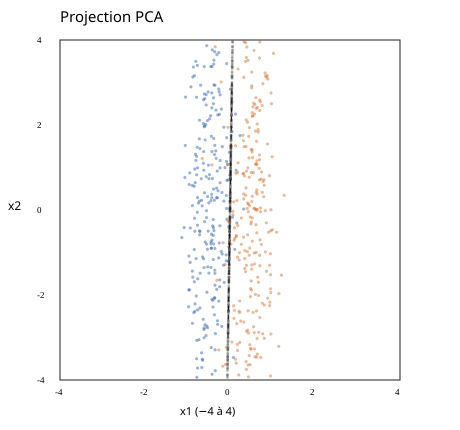

In [60]:
JsonElement cigar;
using (Py.GIL())
{
    // Conserver les 300 points par classe et la graine 42 du terrain « cigar ».
    py.Exec(@"r=np.random.default_rng(42)
S=np.array([[.1,0.],[0.,10.]])
xc=np.vstack([r.multivariate_normal([-.5,0.],S,300),r.multivariate_normal([.5,0.],S,300)])
yc=np.r_[np.zeros(300,dtype=int),np.ones(300,dtype=int)]
lda_c=LinearDiscriminantAnalysis(n_components=1).fit(xc,yc)
pca_c=PCA(n_components=2).fit(xc)
wlda=lda_c.coef_[0]/np.linalg.norm(lda_c.coef_[0]);wpc=pca_c.components_[0]
cigar_json=json.dumps(dict(X=xc.tolist(),y=yc.tolist(),lda=wlda.tolist(),pca=wpc.tolist(),v1=float(xc[:,0].var()),v2=float(xc[:,1].var())))");
    cigar=JsonDocument.Parse(py.Get("cigar_json").As<string>()).RootElement;
}
var cigarX=ReadMatrix(cigar.GetProperty("X"));
var cigarY=ReadInts(cigar.GetProperty("y"));
var ldaAxis=ReadVector(cigar.GetProperty("lda"));
var pcaAxis=ReadVector(cigar.GetProperty("pca"));
string ProjectionPlot(string title,double[] axis)
{
    const int left=60,top=40,width=340,height=340;
    double ScreenX(double x)
    {
        return left+(x+4)*width/8;
    }
    double ScreenY(double y)
    {
        return top+(4-y)*height/8;
    }
    var svg=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='460' height='430'><rect width='100%' height='100%' fill='white'/><defs><clipPath id='clip'><rect x='{left}' y='{top}' width='{width}' height='{height}'/></clipPath></defs><g font-family='sans-serif'><text x='60' y='22' font-size='15'>{title}</text><g clip-path='url(#clip)'>");
    for(int i=0;i<cigarX.Length;i++)
    {
        double x=cigarX[i][0],y=cigarX[i][1];
        double coordinate=x*axis[0]+y*axis[1];
        string fill=cigarY[i]==0 ? "#2458aa" : "#d16a24";
        svg.Append($"<circle cx='{ScreenX(x):0.0}' cy='{ScreenY(y):0.0}' r='1.6' fill='{fill}' fill-opacity='.45'/><circle cx='{ScreenX(coordinate*axis[0]):0.0}' cy='{ScreenY(coordinate*axis[1]):0.0}' r='1.4' fill='#444' fill-opacity='.3'/>");
    }
    svg.Append($"<path d='M{ScreenX(-3*axis[0]):0.0},{ScreenY(-3*axis[1]):0.0}L{ScreenX(3*axis[0]):0.0},{ScreenY(3*axis[1]):0.0}' stroke='#111' stroke-dasharray='5 4'/></g><rect x='{left}' y='{top}' width='{width}' height='{height}' fill='none' stroke='#222'/><text x='180' y='415' font-size='11'>x1 (−4 à 4)</text><text x='8' y='210' font-size='12'>x2</text></g>");
    for(int tick=-4;tick<=4;tick+=2)
    {
        svg.Append($"<text x='{ScreenX(tick)-5:0.0}' y='395' font-size='9'>{tick}</text><text x='37' y='{ScreenY(tick)+3:0.0}' font-size='9'>{tick}</text>");
    }
    svg.Append("</svg>");
    return svg.ToString();
}
Console.WriteLine($"cos(w_LDA,w_PC1)={ldaAxis.Zip(pcaAxis,(a,b)=>a*b).Sum():F4}, variance x1={cigar.GetProperty("v1").GetDouble():F2}, x2={cigar.GetProperty("v2").GetDouble():F2}");
display(new LdaSvg(ProjectionPlot("Projection LDA",ldaAxis)),"image/svg+xml");
display(new LdaSvg(ProjectionPlot("Projection PCA",pcaAxis)),"image/svg+xml");

### Lecture — la géométrie rend l'hypothèse visible

- **Frontières** (régime B) : LDA trace une **droite** (linéaire), QDA une **conique** qui épouse la courbure des classes, la logistique une droite aussi. La géométrie rend l'hypothèse de covariance **visible**.
- **Projection** (jeu « cigar » : classes séparées selon x1 mais variance énorme selon x2) : `cos(w_LDA, w_PC1) ≈ 0`. LDA projette sur l'axe qui **sépare** (x1) ; PC1 sur l'axe de **variance maximale** (x2, 96.5 % de la variance). Deux directions **orthogonales**. La projection supervisée (LDA) choisit l'axe discriminant ; la projection non supervisée (PCA, cf [2.6](2.6-Clustering-KMeans-PCA.ipynb)) choisit l'axe de variance. Quand le signal de classe est porté par une direction de **faible variance** (comme ici), les deux divergents — et c'est LDA qui sépare.


### Exercice 3 — reconnaître le régime

Trois jeux de données simulés sont fournis. Pour chacun dire **quelle hypothèse de covariance** il illustre et **quel modèle** est attendu, puis le vérifier en fitant LDA et QDA.


In [61]:
public record GaussianCase(double[][] Train,int[] TrainLabels,double[][] Test,int[] TestLabels);
(double[][] scores,string explanation) CompareRegimes(GaussianCase[] cases)
{
    // TODO : ajuster LDA et QDA sur chaque jeu, renvoyer trois couples d'accuracy et une explication.
    return (null,null);
}
GaussianCase[] GenerateCases(int seed)
{
    using (Py.GIL())
    {
        py.Set("case_seed",new PyInt(seed));
        py.Exec(@"from sklearn.datasets import make_moons
cs=int(case_seed)
case_specs=[([-1.5,0.],[1.5,0.],[[1.,.6],[.6,1.]],[[1.,.6],[.6,1.]]),([-1.,0.],[1.,0.],[[1.,.85],[.85,1.]],[[1.,-.85],[-.85,1.]])]
case_list=[]
for ma,mb,sa,sb in case_specs:
 xa,ya=make_pair(100,ma,mb,sa,sb,cs);xb,yb=make_pair(500,ma,mb,sa,sb,cs+1)
 case_list.append(dict(train=xa.tolist(),train_y=ya.tolist(),test=xb.tolist(),test_y=yb.tolist()))
xx,yy=make_moons(n_samples=200,noise=.15,random_state=cs)
rr=np.random.default_rng(cs)
xx=np.vstack([xx,rr.normal([3.,2.],[.25,.25],size=(100,2))]);yy=np.r_[yy,np.full(100,2)]
a,b,ya,yb=train_test_split(xx,yy,test_size=.3,random_state=cs,stratify=yy)
case_list.append(dict(train=a.tolist(),train_y=ya.tolist(),test=b.tolist(),test_y=yb.tolist()))
cases_json=json.dumps(case_list)");
        var cases=JsonDocument.Parse(py.Get("cases_json").As<string>()).RootElement;
        return cases.EnumerateArray().Select(v=>new GaussianCase(ReadMatrix(v.GetProperty("train")),ReadInts(v.GetProperty("train_y")),ReadMatrix(v.GetProperty("test")),ReadInts(v.GetProperty("test_y")))).ToArray();
    }
}
var regimeFixtures=new[] {GenerateCases(42),GenerateCases(7)};
var regimeAnswers=regimeFixtures.Select(CompareRegimes).ToArray();
if(regimeAnswers.All(a=>a.scores==null && a.explanation==null))
{
    Console.WriteLine("Exercice 3 à compléter.");
}
else if(regimeAnswers.Any(a=>a.scores==null || a.explanation==null))
{
    Console.WriteLine("Exercice 3 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<regimeFixtures.Length;i++)
    {
        var answer=regimeAnswers[i];
        if(answer.scores.Length!=3 || answer.scores.Any(row=>row==null || row.Length!=2) || answer.explanation.Trim().Length<20)
        {
            ok=false;
            continue;
        }
        for(int j=0;j<3;j++)
        {
            var fixture=regimeFixtures[i][j];
            int[] predictionLda,predictionQda;
            using (Py.GIL())
            {
                py.Set("ex_train",new PyString(JsonSerializer.Serialize(fixture.Train)));
                py.Set("ex_ytrain",new PyString(JsonSerializer.Serialize(fixture.TrainLabels)));
                py.Set("ex_test",new PyString(JsonSerializer.Serialize(fixture.Test)));
                py.Exec(@"et=np.asarray(json.loads(ex_train));ey=np.asarray(json.loads(ex_ytrain));ev=np.asarray(json.loads(ex_test))
case_result=json.dumps(dict(lda=LinearDiscriminantAnalysis().fit(et,ey).predict(ev).tolist(),qda=QuadraticDiscriminantAnalysis().fit(et,ey).predict(ev).tolist()))");
                var result=JsonDocument.Parse(py.Get("case_result").As<string>()).RootElement;
                predictionLda=ReadInts(result.GetProperty("lda"));
                predictionQda=ReadInts(result.GetProperty("qda"));
            }
            var expected=new[] {predictionLda.Select((v,k)=>v==fixture.TestLabels[k]?1.0:0.0).Average(),predictionQda.Select((v,k)=>v==fixture.TestLabels[k]?1.0:0.0).Average()};
            ok=ok && answer.scores[j].Zip(expected,(v,e)=>double.IsFinite(v) && Math.Abs(v-e)<1e-10).All(v=>v);
        }
    }
    Console.WriteLine(ok ? "Exercice 3 : mesures cohérentes ; examiner les hypothèses et la justification" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


### 5. Calibration et matrices de confusion — pas accuracy seule

Deux modèles peuvent avoir **la même accuracy** mais des probabilités très différentes : l'un sera bien calibré (une prédiction à 70 % est correcte ~70 % du temps), l'autre non. [2.5](2.5-Biais-Variance-CV-ROC.ipynb) introduisait la courbe ROC ; ici on regarde la **fiabilité** (calibration) et la **matrice de confusion** — pas seulement le taux de bien classés.


### Lire une courbe de fiabilité avant de la lire

L'instrument de cette section : le **diagramme de fiabilité** et le **score de Brier**. Pour chaque bac de probabilité prédite (cinq bacs uniformes : 0–0,2, 0,2–0,4, …), on trace la fréquence *observée* de la classe positive contre la probabilité *prédite* : un modèle parfaitement calibré suit la diagonale. Au-dessus de la diagonale il sous-estime, en dessous il surestime — et un modèle peut avoir une bonne accuracy tout en étant **systématiquement trop confiant**. Le Brier mesure la qualité probabiliste globale, mêlant notamment calibration et résolution, en un nombre : la moyenne des carrés des écarts entre probabilité prédite et réalisation (0/1) — plus bas est mieux, et un modèle confiant-qui-se-trompe y est lourdement pénalisé. Gardez les deux à l'œil sur les sorties qui suivent.

LDA          Brier=0.1125, accuracy=0.8313


QDA          Brier=0.0469, accuracy=0.9250


logistique   Brier=0.1129, accuracy=0.8313


NaiveBayes   Brier=0.1124, accuracy=0.8375


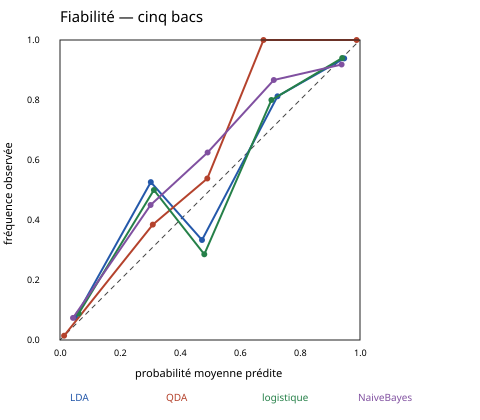

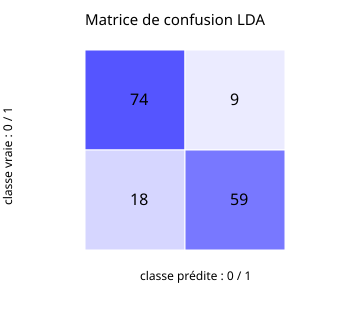

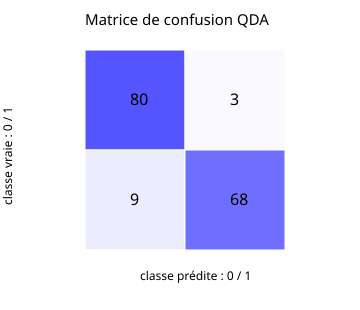

In [62]:
using (Py.GIL())
{
    // Même split de validation : 40 % du train du régime B, graine zéro.
    py.Exec("calXtr,calXval,calYtr,calYval=train_test_split(XtrB,ytrB,test_size=.4,random_state=0)");
}
var calibrationModels=new[] { "LDA", "QDA", "logistique", "NaiveBayes" };
var calibrationColors=new[] { "#2458aa", "#b4422c", "#258048", "#8050a0" };
var reliability=new List<(double predicted,double observed)>[4];
var confusions=new Dictionary<string,int[,]>();
for(int modelIndex=0;modelIndex<calibrationModels.Length;modelIndex++)
{
    double[] probability;
    int[] actual,predicted;
    using (Py.GIL())
    {
        py.Set("model_name",new PyString(calibrationModels[modelIndex]));
        py.Exec(@"cm=models[str(model_name)]().fit(calXtr,calYtr)
cal_json=json.dumps(dict(p=cm.predict_proba(calXval)[:,1].tolist(),y=calYval.tolist(),pred=cm.predict(calXval).tolist()))");
        var result=JsonDocument.Parse(py.Get("cal_json").As<string>()).RootElement;
        probability=ReadVector(result.GetProperty("p"));
        actual=ReadInts(result.GetProperty("y"));
        predicted=ReadInts(result.GetProperty("pred"));
    }
    double brier=probability.Select((value,i)=>Math.Pow(value-actual[i],2)).Average();
    double accuracy=predicted.Select((value,i)=>value==actual[i]?1.0:0.0).Average();
    var confusion=new int[2,2];
    for(int i=0;i<actual.Length;i++)
    {
        confusion[actual[i],predicted[i]]++;
    }
    confusions[calibrationModels[modelIndex]]=confusion;
    reliability[modelIndex]=new List<(double predicted,double observed)>();
    for(int bin=0;bin<5;bin++)
    {
        // Compter les bornes k×(1/5) strictement inférieures à p : searchsorted à gauche.
        var indices=Enumerable.Range(0,probability.Length).Where(i=>Enumerable.Range(1,4).Count(k=>k*(1.0/5.0)<probability[i])==bin).ToArray();
        if(indices.Length>0)
        {
            reliability[modelIndex].Add((indices.Average(i=>probability[i]),indices.Average(i=>(double)actual[i])));
        }
    }
    Console.WriteLine($"{calibrationModels[modelIndex],-12} Brier={brier:F4}, accuracy={accuracy:F4}");
}
string ReliabilityPlot()
{
    const int left=60,top=40,size=300;
    double X(double value)
    {
        return left+value*size;
    }
    double Y(double value)
    {
        return top+(1-value)*size;
    }
    var svg=new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='480' height='420'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='60' y='22' font-size='15'>Fiabilité — cinq bacs</text>");
    svg.Append($"<path d='M{X(0)},{Y(0)}L{X(1)},{Y(1)}' stroke='#444' stroke-dasharray='5 4'/>");
    for(int t=0;t<=5;t++)
    {
        double v=t/5.0;
        svg.Append($"<text x='{X(v)-6:0.0}' y='356' font-size='9'>{v:F1}</text><text x='27' y='{Y(v)+3:0.0}' font-size='9'>{v:F1}</text>");
    }
    for(int m=0;m<calibrationModels.Length;m++)
    {
        string points=String.Join(" ",reliability[m].Select(p=>$"{X(p.predicted):0.0},{Y(p.observed):0.0}"));
        svg.Append($"<polyline points='{points}' fill='none' stroke='{calibrationColors[m]}' stroke-width='2'/>");
        foreach(var point in reliability[m])
        {
            svg.Append($"<circle cx='{X(point.predicted):0.0}' cy='{Y(point.observed):0.0}' r='3' fill='{calibrationColors[m]}'/>");
        }
        svg.Append($"<text x='{70+m*96}' y='401' font-size='10' fill='{calibrationColors[m]}'>{calibrationModels[m]}</text>");
    }
    svg.Append($"<rect x='{left}' y='{top}' width='{size}' height='{size}' fill='none' stroke='#222'/><text x='135' y='377' font-size='11'>probabilité moyenne prédite</text><text x='12' y='245' font-size='11' transform='rotate(-90 12 245)'>fréquence observée</text></g></svg>");
    return svg.ToString();
}
string ConfusionPlot(string name,int[,] counts)
{
    const int left=85,top=50,size=200;
    int maximum=counts.Cast<int>().Max();
    var svg=new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='360' height='310'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='85' y='25' font-size='15'>Matrice de confusion {name}</text>");
    for(int row=0;row<2;row++)
    {
        for(int col=0;col<2;col++)
        {
            int v=counts[row,col];
            int shade=255-(int)(170.0*v/Math.Max(1,maximum));
            svg.Append($"<rect x='{left+col*size/2}' y='{top+row*size/2}' width='{size/2}' height='{size/2}' fill='rgb({shade},{shade},255)' stroke='white'/><text x='{left+col*size/2+45}' y='{top+row*size/2+55}' font-size='16'>{v}</text>");
        }
    }
    svg.Append("<text x='140' y='280' font-size='12'>classe prédite : 0 / 1</text><text x='12' y='205' font-size='12' transform='rotate(-90 12 205)'>classe vraie : 0 / 1</text></g></svg>");
    return svg.ToString();
}
display(new LdaSvg(ReliabilityPlot()),"image/svg+xml");
display(new LdaSvg(ConfusionPlot("LDA",confusions["LDA"])),"image/svg+xml");
display(new LdaSvg(ConfusionPlot("QDA",confusions["QDA"])),"image/svg+xml");

### Lecture — la calibration n'est pas l'accuracy

- **QDA** (Brier 0.0469, acc 0.9250) obtient ici le meilleur Brier et la meilleure accuracy observés ; ces deux chiffres ne prouvent pas à eux seuls une calibration parfaite : son hypothèse (Σ propres) correspond à la construction du régime B. Un meilleur Brier et une meilleure accuracy ne garantissent pas que chaque bac corresponde aux fréquences observées : la courbe montre notamment un bac autour de 0,68 prédit pour une fréquence observée de 1.
- **LDA** (0.1124, 0.8313) et **logistique** (0.1129, 0.8313) : même accuracy, tous deux moins précis et de Brier plus élevé sur ce split — la frontière fausse biaise leurs probabilités.
- **Naive Bayes** (acc 0.8375) : l'accuracy la plus haute des « mauvaises hypothèses » mais Brier 0.1124 (comme LDA) — de Brier comparable à LDA sur ce split.
- L'accuracy seule ne dit rien de la **fiabilité des probabilités** : deux modèles peuvent partager 0.8313 d'accuracy et différer en calibration. C'est la courbe de fiabilité et le Brier qui le montrent.


### 6. Grande dimension, singularité, régularisation — le coût de QDA

QDA estime **une covariance complète par classe** : c'est `d(d+1)/2` paramètres par classe, contre `d(d+1)/2` **au total** pour LDA (une covariance complète **partagée** par les classes) et `d` par classe pour Naive Bayes (diagonale). En dimension `d`, seul Naive Bayes reste linéaire en `O(d)` : LDA comme QDA estiment une matrice complète, en `O(d²)` — ce qui les sépare est le **nombre** de ces matrices (une pour LDA, une par classe pour QDA), pas leur taille. Le coût explose — et une covariance empirique centrée a un rang au plus `n_c−1` ; elle est donc singulière si `d ≥ n_c`, et le rang mesuré permet de détecter d'autres causes de singularité.


### Ce que le diagnostic mesure avant de le voir

La dernière expérience fixe le nombre de points par classe et fait croître la dimension `d` : 2, 5, 10, 20, 30. Pour chaque `d`, le tableau comptera les **paramètres** estimés par chaque modèle, leur **accuracy**, et un drapeau de **covariance singulière** — le moment exact où estimer une covariance de classe par classe devient impossible faute de points. C'est le talon d'Achille de QDA annoncé : chaque covariance propre coûte de l'ordre de `d²` paramètres, et l'inverse d'une matrice estimée sur trop peu de points n'existe plus. Regardez la colonne du drapeau tourner — c'est elle qui datéra l'effondrement.

In [63]:
// Mesurer le rang de chaque covariance de classe et conserver le statut effectif de QDA.
using (Py.GIL())
{
    py.Exec(@"def make_highdim(d,n_c,seed):
 r=np.random.default_rng(seed)
 x0=r.multivariate_normal(np.zeros(d),np.eye(d),n_c)
 x1=r.multivariate_normal(np.ones(d),np.eye(d),n_c)
 return np.vstack([x0,x1]),np.r_[np.zeros(n_c,dtype=int),np.ones(n_c,dtype=int)]
from scipy.linalg import LinAlgWarning");
}
Console.WriteLine(" d | paramètres LDA | QDA | NB | accuracy LDA | QDA | NB | rang covariance | statut QDA");
foreach(int dimension in new[] {2,5,10,20,30})
{
    int[] actual;
    int[] ranks;
    using (Py.GIL())
    {
        py.Set("dimension",new PyInt(dimension));
        py.Exec(@"Xh,yh=make_highdim(int(dimension),30,42)
Xh_test,yh_test=make_highdim(int(dimension),500,7)
high_json=json.dumps(dict(y=yh_test.tolist(),ranks=[int(np.linalg.matrix_rank(np.cov(Xh[yh==c],rowvar=False))) for c in (0,1)]))");
        var data=JsonDocument.Parse(py.Get("high_json").As<string>()).RootElement;
        actual=ReadInts(data.GetProperty("y"));
        ranks=ReadInts(data.GetProperty("ranks"));
    }
    var scores=new Dictionary<string,double?>();
    string qdaStatus="ok";
    foreach(string method in new[] {"LDA","QDA","NaiveBayes"})
    {
        try
        {
            int[] prediction;
            using (Py.GIL())
            {
                py.Set("model_name",new PyString(method));
                py.Exec(@"with warnings.catch_warnings():
 warnings.filterwarnings('ignore',category=LinAlgWarning)
 hm=models[str(model_name)]().fit(Xh,yh)
 high_pred=json.dumps(hm.predict(Xh_test).tolist())");
                prediction=ReadInts(JsonDocument.Parse(py.Get("high_pred").As<string>()).RootElement);
            }
            scores[method]=prediction.Select((v,i)=>v==actual[i]?1.0:0.0).Average();
        }
        catch(PythonException error)
        {
            scores[method]=null;
            if(method=="QDA") qdaStatus=$"erreur: {error.Message.Split('\n')[0]}";
            else throw;
        }
    }
    int ldaParameters=2*dimension+dimension*(dimension+1)/2+1;
    int qdaParameters=2*dimension+dimension*(dimension+1)+1;
    int nbParameters=4*dimension+1;
    Console.WriteLine($"{dimension,2} | {ldaParameters,5} | {qdaParameters,5} | {nbParameters,5} | {scores["LDA"],6:F3} | {scores["QDA"],6:F3} | {scores["NaiveBayes"],6:F3} | {ranks.Min()}/{dimension} | {qdaStatus}");
}

 d | paramètres LDA | QDA | NB | accuracy LDA | QDA | NB | rang covariance | statut QDA


 2 |     8 |    11 |     9 |  0.769 |  0.772 |  0.776 | 2/2 | ok


 5 |    26 |    41 |    21 |  0.856 |  0.825 |  0.849 | 5/5 | ok


10 |    76 |   131 |    41 |  0.910 |  0.900 |  0.927 | 10/10 | ok


20 |   251 |   461 |    81 |  0.956 |  0.834 |  0.981 | 20/20 | ok


30 |   526 |   991 |   121 |  0.975 |        |  0.994 | 29/30 | erreur: The covariance matrix of class 0 is not full rank. When using `solver='svd'` the number of samples in each class should be more than the number of features, but class 0 has 30 samples and 30 features. Try using `solver='eigen'` and setting the parameter `shrinkage` for regularization.


### Lecture — le mur de la dimension

Le coût se lit dans le tableau :

- **Paramètres** (k=2 classes) : LDA ≈ d²/2 (cov partagée), QDA ≈ d² (deux covariances), NB ≈ 4d (diagonal). À d=30 : LDA 526, QDA 991, NB 121. **QDA est ~2× LDA**, Naive Bayes reste **linéaire**.
- **Accuracy** : d=2..10 → LDA/QDA/NB proches (0.77–0.93) ; à **d=20** QDA décroche (0.833 vs LDA 0.956, NB 0.981) ; à **d=30** le drapeau tourne — la covariance par classe est **singulière** (rang < d) — et le score QDA est indisponible après erreur du solveur, tandis que LDA 0.975 et NB 0.994 survivent.
- Le **mur** : quand d ≥ n_c, la covariance empirique centrée ne peut pas être de rang plein ; le rang mesuré et le statut du solveur permettent de diagnostiquer cette instance → effondrement. Ce que fait sklearn à ce moment dépend de sa version : il peut lever, comme ici (le score n'est alors pas rendu), ou poursuivre le calcul malgré la singularité et renvoyer un score effondré qu'aucune erreur ne signale. La colonne du drapeau, elle, est mesurée sur le **rang** de la covariance — elle date le mur dans les deux cas, indépendamment de la version. LDA (covariance partagée + solveur SVD) survit ; Naive Bayes (diagonal, 4d paramètres) est le plus robuste. C'est le **prix de la flexibilité** : la frontière quadratique coûte d² paramètres, et en grande dimension ce coût devient une **singularité**.


## À retenir

Le modèle gaussien relie deux façons de décider :

- **Hypothèse de covariance partagée** → frontière **linéaire** (LDA), `d(d+1)/2` paramètres pour la matrice commune — `O(d²)` mais `k` fois moins que QDA, qui en estime une par classe (la moitié à deux classes) — robuste en petit `n`. C'est le bon modèle quand les classes sont **raisonnablement homoscédastiques**.
- **Hypothèse de covariances propres** → frontière **quadratique** (QDA), `O(d²)` paramètres, coûteux et fragile dès que `n_c` approche `d`. C'est le bon modèle quand la **forme** des classes diffère.
- **Naive Bayes** ([2.3b](2.3b-Naive-Bayes-Generatif.ipynb)) est le cas diagonal — encore plus restrictif, mais le plus économe.

La **frontière** est la signature visible de l'hypothèse, et sur le jeu cigar, la **projection discriminante** (LDA) sépare les classes mieux que la projection de variance maximale ([2.6](2.6-Clustering-KMeans-PCA.ipynb)). Le bon choix n'est pas « le modèle qui a le plus de paramètres » mais **celui dont l'hypothèse de covariance colle aux données** — mesurable, pas raconté.


| Concept | Mesure dans ce carnet |
|---|---|
| « De zéro » vérifié | accuracy `0.98` des deux côtés ; `w` from scratch `[4.877 ; -2.913]` contre `[4.889 ; -2.92]` pour sklearn, `cos = 1.0`, intercept `-0.358` |
| Régime A (covariance partagée, n=200/classe) | LDA `0.9698`, QDA `0.9695`, logistique `0.9697`, NB `0.9332` — LDA, QDA et logistique sont proches ; NB est en retrait sur ce régime |
| Régime B (covariances propres, n=200/classe) | QDA `0.9004` contre LDA `0.8434` : la frontière quadratique gagne quand sa souplesse est méritée |
| Régime C (covariances propres, n=5/classe) | QDA `0.8373 ± 0.0571` contre LDA `0.8166 ± 0.0599` : l'écart se resserre et la variance explose |
| Calibration ≠ accuracy | split commun (régime B) : QDA `Brier 0.0469` / acc `0.9250` contre LDA `0.1124` / `0.8313` |
| L'axe discriminant n'est pas l'axe de variance | `cos(w_LDA, w_PC1) = -0.0004` ; variance `0.35` selon x1 contre `9.73` selon x2 |
| Le mur de la dimension | QDA estime une covariance par classe (`O(d²)` paramètres) : le diagnostic de la section 6 le montre s'effondrer quand `d` approche puis dépasse `n` par classe |

**La leçon transférable.** La frontière est la signature visible de l'hypothèse : partagée, elle est linéaire ; propres, elle est quadratique ; diagonale, on retrouve Naive Bayes. Le bon choix n'est pas « le modèle qui a le plus de paramètres » mais celui dont l'hypothèse de covariance colle aux données — mesurable, pas raconté.

**Transition.** Le carnet suivant, [2.4-Arbres-Forets-Ensembles](2.4-Arbres-Forets-Ensembles.ipynb), quitte les modèles gaussiens pour des modèles qui ne postulent aucune forme : les arbres, et les ensembles qui les combinent.

## Vérifiez votre compréhension

**1. Dans le régime A, LDA, QDA et logistique se tiennent dans `0.003` (0,9695 à 0,9698), tandis que NB vaut 0,9332. Pourquoi QDA, plus souple, ne gagne-t-il pas ?**

<details>
<summary>Réponse</summary>

La covariance partagée est vraie par construction ; sous le modèle gaussien et ses priors, la frontière de Bayes est linéaire. Sur ces 20 tirages, LDA et QDA obtiennent des moyennes proches tandis que NB est plus bas. Cela ne prouve pas que la variance d'estimation soit l'unique cause de l'écart ni que cette comparaison se généralise à d'autres données.
</details>

**2. Dans le régime B, LDA perd `0.057` d'accuracy contre QDA. Que suggère cet écart sur ce régime, et que ne prouve-t-il pas ?**

<details>
<summary>Réponse</summary>

La covariance commune impose une frontière linéaire alors que les distributions du régime B ont des covariances différentes. Cet écart observé suggère un effet de spécification, mais les deux erreurs mêlent aussi l'estimation sur échantillon fini. Il ne démontre pas qu'augmenter n laisserait la frontière inchangée ni que QDA gagnerait sur toute autre distribution.
</details>

**3. Sur le split commun du régime B, Naive Bayes affiche `acc 0.8375` contre `0.8313` à LDA — mais le même Brier `0.1124`. Qu'est-ce que l'accuracy ne voit pas ici ?**

<details>
<summary>Réponse</summary>

L'accuracy ne regarde que la décision au seuil 0,5 : deux modèles peuvent y être quasi équivalents tandis que leurs probabilités diffèrent en qualité. Le Brier, lui, pénalise toute la distribution prédite — ici, il révèle que le score observé (`0.1124`) résume erreur probabiliste mais ne prouve pas à lui seul si les probabilités sont exploitables, là où QDA (`0.0469`) est deux fois meilleur à qualité de décision voisine ou supérieure (`0.9250`). Pour un usage en risque (seuils métier, priorisation), il faut examiner ensemble Brier, calibration, discrimination et contexte d'usage — le sujet complet est traité dans [2.5b-Calibration-Probabilites](2.5b-Calibration-Probabilites.ipynb).
</details>

## Pour aller plus loin

- [README de la sous-série 02-ML-Cours](README.md) — la carte des carnets et de leurs concepts-phares.
- [README de la série DataScienceWithAgents](../README.md) — le rôle de ce socle ML dans la formation.
- [2.4-Arbres-Forets-Ensembles](2.4-Arbres-Forets-Ensembles.ipynb) — la suite immédiate : des modèles sans hypothèse de forme.
- [2.3b-Naive-Bayes-Generatif](2.3b-Naive-Bayes-Generatif.ipynb) — le cas diagonal de la même famille générative.
- [2.6-Clustering-KMeans-PCA](2.6-Clustering-KMeans-PCA.ipynb) — l'axe de variance maximale que la projection discriminante domine ici pour séparer les classes.

## Références

* Deisenroth, M.P., Faisal, A.A. & Ong, C.S. (2020). *Mathematics for
Machine Learning*. Cambridge UP. — ch. 6 pose les distributions
gaussiennes multivariées (matrice de covariance, densité
conditionnelle) qui sous-tendent LDA/QDA ; ch. 9 unifie avec la
régression linéaire gaussienne (estimateur du maximum a posteriori
= ridge). Le lien entre ces deux chapitres est précisément ce que
ce carnet fait toucher du doigt aux étudiants.

